# Sales Data Analysis

### Exploratory Data Analysis using Python

**Dataset:** Sample Superstore

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

**Objective:** To analyze sales, profit, discounts, product categories, and regional performance to identify meaningful business insights.

## 1. Environment Setup and Library Installation

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")

C:\Users\Dell\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Dell\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


All Libraries Imported Successfully!


## 2. Loading the Dataset

In [3]:
# Load the Superstore Dataset

df = pd.read_csv("../Dataset/SampleSuperstore.csv")

# Display first 5 rows
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


## 3. Data Understanding and Initial Inspection

This section examines the dataset dimensions, column names, data types, summary statistics, and initial records.

In [4]:
# Check number of rows and columns

df.shape

(9994, 13)

In [5]:
# Display all column names

df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [6]:
# Check dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   str    
 1   Segment       9994 non-null   str    
 2   Country       9994 non-null   str    
 3   City          9994 non-null   str    
 4   State         9994 non-null   str    
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   str    
 7   Category      9994 non-null   str    
 8   Sub-Category  9994 non-null   str    
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), str(8)
memory usage: 1.7 MB


In [7]:
# Generate descriptive statistics

df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 4. Data Quality Assessment and Cleaning

We check missing values, duplicate records, and categorical values. Exact duplicate rows are removed; the dataset has no missing values.

In [8]:
# Check missing values

df.isnull().sum()

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [9]:
# Check duplicate records
df.duplicated().sum()

17

In [10]:
# Check unique values in categorical columns
categorical_columns = df.select_dtypes(include='str').columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Ship Mode:
<ArrowStringArray>
['Second Class', 'Standard Class', 'First Class', 'Same Day']
Length: 4, dtype: str

Segment:
<ArrowStringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str

Country:
<ArrowStringArray>
['United States']
Length: 1, dtype: str

City:
<ArrowStringArray>
[        'Henderson',       'Los Angeles',   'Fort Lauderdale',
           'Concord',           'Seattle',        'Fort Worth',
           'Madison',       'West Jordan',     'San Francisco',
           'Fremont',
 ...
        'Hagerstown',       'East Orange', 'Arlington Heights',
            'Oswego',       'Coon Rapids',      'San Clemente',
   'San Luis Obispo',        'Springdale',              'Lodi',
             'Mason']
Length: 531, dtype: str

State:
<ArrowStringArray>
[            'Kentucky',           'California',              'Florida',
       'North Carolina',           'Washington',                'Texas',
            'Wisconsin',                 'Utah',             'Nebras

In [11]:
# Create a backup of the original dataset
df_original = df.copy()

# Remove duplicate records
df = df.drop_duplicates()

print("Original rows:", len(df_original))
print("Rows after removing duplicates:", len(df))
print("Duplicates remaining:", df.duplicated().sum())

Original rows: 9994
Rows after removing duplicates: 9977
Duplicates remaining: 0


## 5. Outlier Detection

Outliers are identified using boxplots and the IQR method. These records are retained because extreme sales or profit values may represent valid business transactions; they are not automatically deleted.

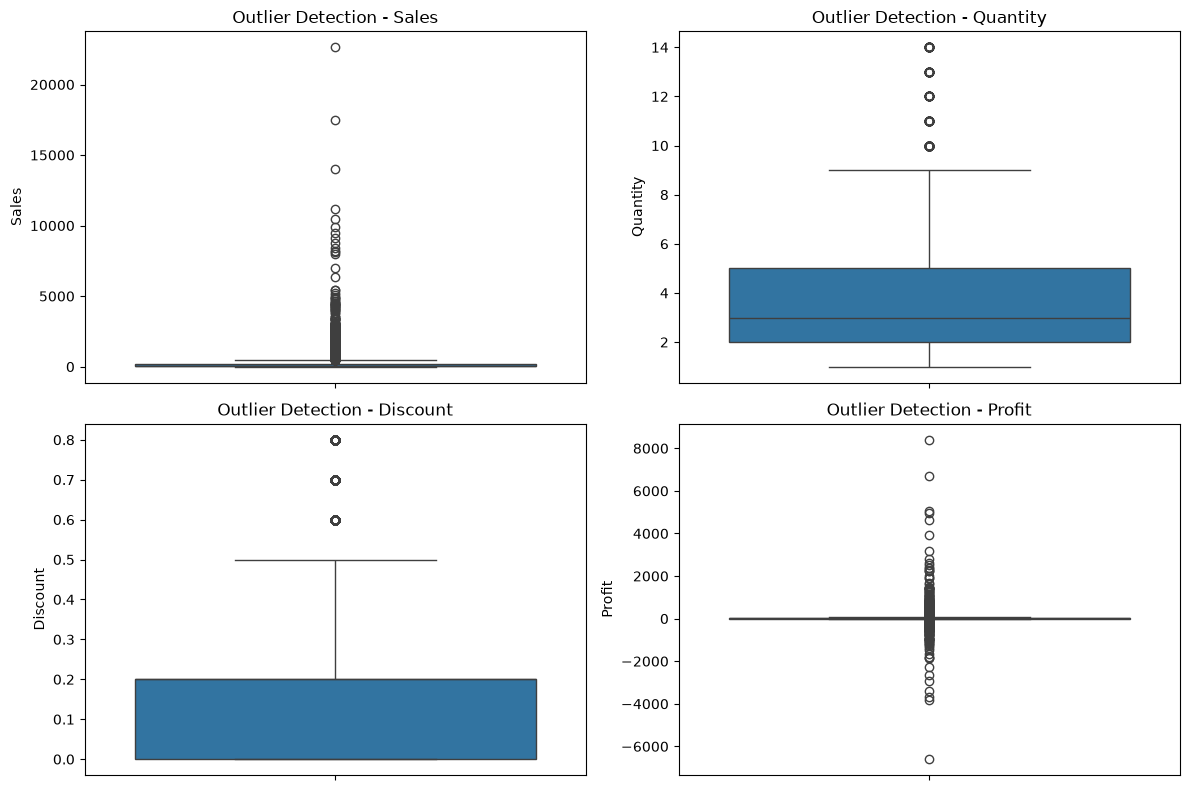

In [12]:
# Select numerical columns
numerical_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

# Create boxplots to detect outliers
plt.figure(figsize=(12, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f'Outlier Detection - {col}')

plt.tight_layout()
plt.show()

In [13]:
# Calculate outliers using IQR method

numerical_columns = ['Sales', 'Quantity', 'Discount', 'Profit']

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"{col}: {len(outliers)} outliers")

Sales: 1167 outliers
Quantity: 170 outliers
Discount: 855 outliers
Profit: 1881 outliers


In [14]:
# Check unique values in important columns

print("Ship Mode:", df['Ship Mode'].unique())
print("Segment:", df['Segment'].unique())
print("Region:", df['Region'].unique())
print("Category:", df['Category'].unique())

Ship Mode: <ArrowStringArray>
['Second Class', 'Standard Class', 'First Class', 'Same Day']
Length: 4, dtype: str
Segment: <ArrowStringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str
Region: <ArrowStringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str
Category: <ArrowStringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


## 6. Feature Engineering

New analytical features are created: row-level profit margin, sales category, and profit/loss status.

In [15]:
# Feature Engineering

# 1. Calculate Profit Margin
df['Profit_Margin'] = (df['Profit'] / df['Sales']) * 100

# 2. Categorize Sales
df['Sales_Category'] = pd.cut(
    df['Sales'],
    bins=[0, 100, 500, float('inf')],
    labels=['Low', 'Medium', 'High']
)

# 3. Identify Profit or Loss
df['Profit_Status'] = df['Profit'].apply(
    lambda x: 'Profit' if x > 0 else ('Loss' if x < 0 else 'No Profit')
)

# Display new features
df[['Sales', 'Profit', 'Profit_Margin',
    'Sales_Category', 'Profit_Status']].head(10)

,Sales,Profit,Profit_Margin,Sales_Category,Profit_Status
0,261.9600,41.9136,16.00,Medium,Profit
1,731.9400,219.5820,30.00,High,Profit
2,14.6200,6.8714,47.00,Low,Profit
3,957.5775,-383.0310,-40.00,High,Loss
4,22.3680,2.5164,11.25,Low,Profit
5,48.8600,14.1694,29.00,Low,Profit
6,7.2800,1.9656,27.00,Low,Profit
7,907.1520,90.7152,10.00,High,Profit
8,18.5040,5.7825,31.25,Low,Profit
9,114.9000,34.4700,30.00,Medium,Profit


## 7. Categorical Encoding

One-hot encoding is applied to selected categorical variables. The encoded dataset is stored separately as `df_encoded`, while `df` remains available for analysis.

In [16]:
# Select categorical columns for encoding
encoding_columns = [
    'Ship Mode',
    'Segment',
    'Region',
    'Category',
    'Sub-Category'
]

# Apply One-Hot Encoding
df_encoded = pd.get_dummies(
    df,
    columns=encoding_columns,
    drop_first=True,
    dtype=int
)

# Check the results
print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)

df_encoded.head()

Original dataset shape: (9977, 16)
Encoded dataset shape: (9977, 37)


,Country,City,State,Postal Code,Sales,Quantity,Discount,Profit,Profit_Margin,Sales_Category,...,Sub-Category_Envelopes,Sub-Category_Fasteners,Sub-Category_Furnishings,Sub-Category_Labels,Sub-Category_Machines,Sub-Category_Paper,Sub-Category_Phones,Sub-Category_Storage,Sub-Category_Supplies,Sub-Category_Tables
0,United States,Henderson,Kentucky,42420,261.9600,2,0.00,41.9136,16.00,Medium,...,0,0,0,0,0,0,0,0,0,0
1,United States,Henderson,Kentucky,42420,731.9400,3,0.00,219.5820,30.00,High,...,0,0,0,0,0,0,0,0,0,0
2,United States,Los Angeles,California,90036,14.6200,2,0.00,6.8714,47.00,Low,...,0,0,0,1,0,0,0,0,0,0
3,United States,Fort Lauderdale,Florida,33311,957.5775,5,0.45,-383.0310,-40.00,High,...,0,0,0,0,0,0,0,0,0,1
4,United States,Fort Lauderdale,Florida,33311,22.3680,2,0.20,2.5164,11.25,Low,...,0,0,0,0,0,0,0,1,0,0


## 8. Exploratory Data Analysis (EDA)

This section explores descriptive statistics and sales/profit patterns across product categories, regions, discounts, sub-categories, shipping modes, and customer segments.

In [17]:
# Descriptive Statistics

df[['Sales', 'Profit', 'Quantity',
    'Discount', 'Profit_Margin']].describe()

,Sales,Profit,Quantity,Discount,Profit_Margin
count,9977.000000,9977.00000,9977.000000,9977.000000,9977.000000
mean,230.148902,28.69013,3.790719,0.156278,12.011354
std,623.721409,234.45784,2.226657,0.206455,46.663769
min,0.444000,-6599.97800,1.000000,0.000000,-275.000000
25%,17.300000,1.72620,2.000000,0.000000,7.500000
50%,54.816000,8.67100,3.000000,0.200000,27.000000
75%,209.970000,29.37200,5.000000,0.200000,36.250000
max,22638.480000,8399.97600,14.000000,0.800000,50.000000


### 8.1 Sales by Product Category

Category
Furniture          741306.3133
Office Supplies    718735.2440
Technology         836154.0330
Name: Sales, dtype: float64


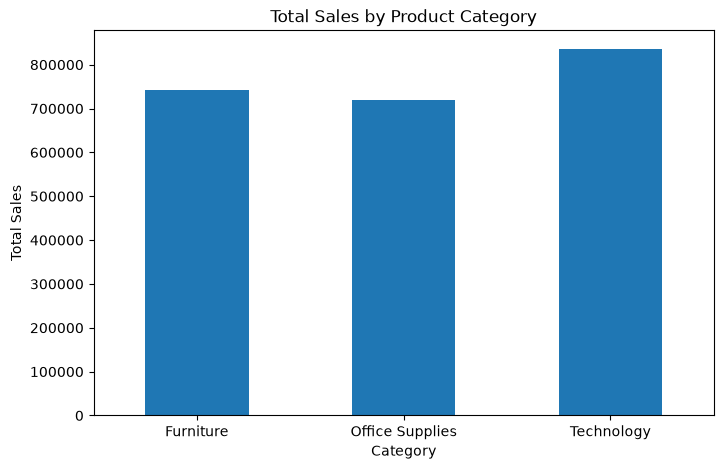

In [18]:
# Total Sales by Category

category_sales = df.groupby('Category', observed=True)['Sales'].sum()

print(category_sales)

category_sales.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Product Category',
    xlabel='Category',
    ylabel='Total Sales'
)

plt.xticks(rotation=0)
plt.savefig('../Visualizations/Category_Sales.png', bbox_inches='tight')
plt.show()

### 8.2 Profit by Product Category

Category
Furniture           18421.8137
Office Supplies    122364.6608
Technology         145454.9481
Name: Profit, dtype: float64


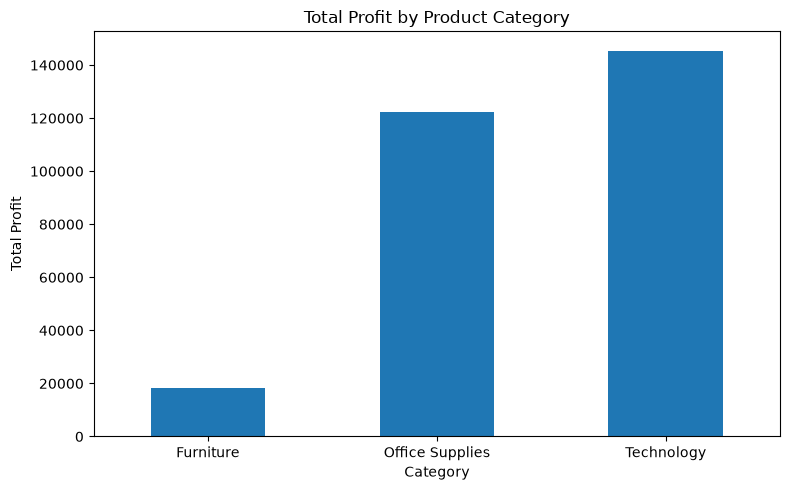

In [19]:
# Total Profit by Category

category_profit = df.groupby(
    'Category',
    observed=True
)['Profit'].sum()

print(category_profit)

category_profit.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Profit by Product Category',
    xlabel='Category',
    ylabel='Total Profit'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../Visualizations/Category_Profit.png', bbox_inches='tight')
plt.show()

### 8.3 Sales by Region

Region
Central    500782.8528
East       678435.1960
South      391721.9050
West       725255.6365
Name: Sales, dtype: float64


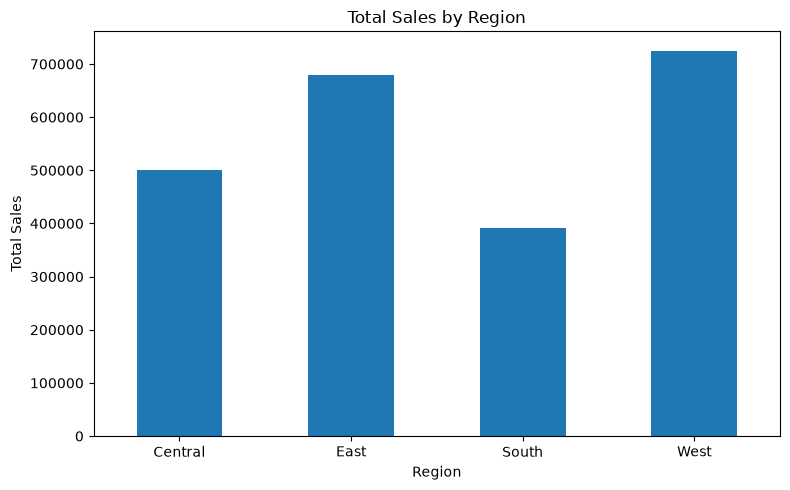

In [20]:
# Total Sales by Region

region_sales = df.groupby('Region')['Sales'].sum()

print(region_sales)

region_sales.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Region',
    xlabel='Region',
    ylabel='Total Sales'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../Visualizations/Region_Sales.png', bbox_inches='tight')
plt.show()

### 8.4 Profit by Region

Region
Central     39655.8752
East        91506.3092
South       46749.4303
West       108329.8079
Name: Profit, dtype: float64


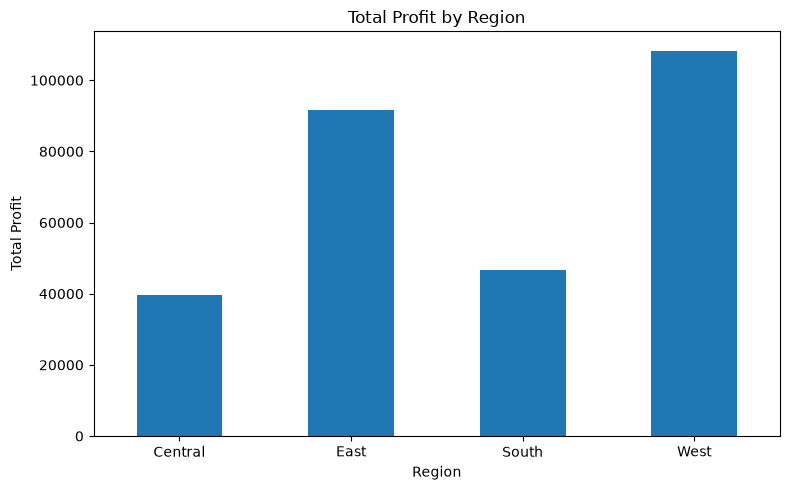

In [21]:
# Total Profit by Region

region_profit = df.groupby('Region')['Profit'].sum()

print(region_profit)

region_profit.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Profit by Region',
    xlabel='Region',
    ylabel='Total Profit'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../Visualizations/Region_Profit.png', bbox_inches='tight')
plt.show()

### 8.5 Average Profit by Discount

Discount
0.00     67.024108
0.10     96.055074
0.15     27.288298
0.20     24.721217
0.30    -45.828401
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -102.116395
Name: Profit, dtype: float64


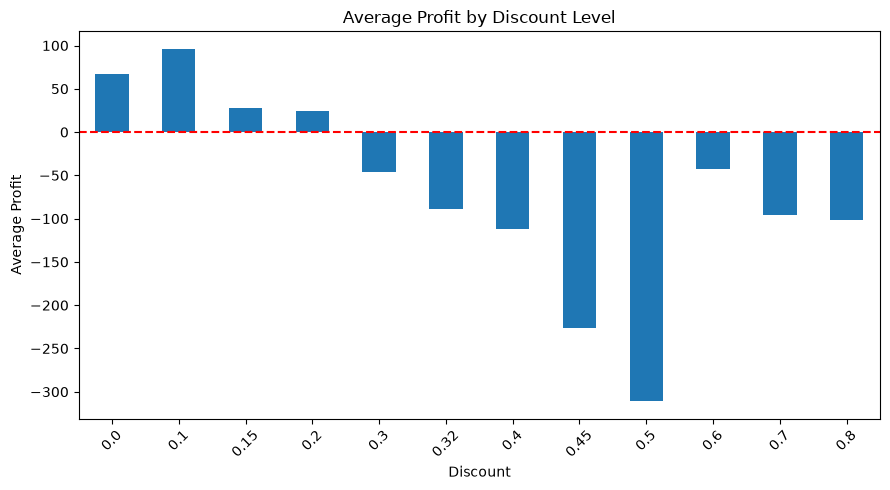

In [22]:
# Average Profit by Discount

discount_profit = df.groupby('Discount')['Profit'].mean()

print(discount_profit)

discount_profit.plot(
    kind='bar',
    figsize=(9, 5),
    title='Average Profit by Discount Level',
    xlabel='Discount',
    ylabel='Average Profit'
)

plt.axhline(0, color='red', linestyle='--')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../Visualizations/Discount_Analysis.png', bbox_inches='tight')
plt.show()

### 8.6 Most Profitable Sub-Categories

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          33944.2395
Binders        30228.0003
Chairs         26567.1278
Storage        21278.8264
Appliances     18138.0054
Furnishings    13052.7230
Envelopes       6964.1767
Name: Profit, dtype: float64


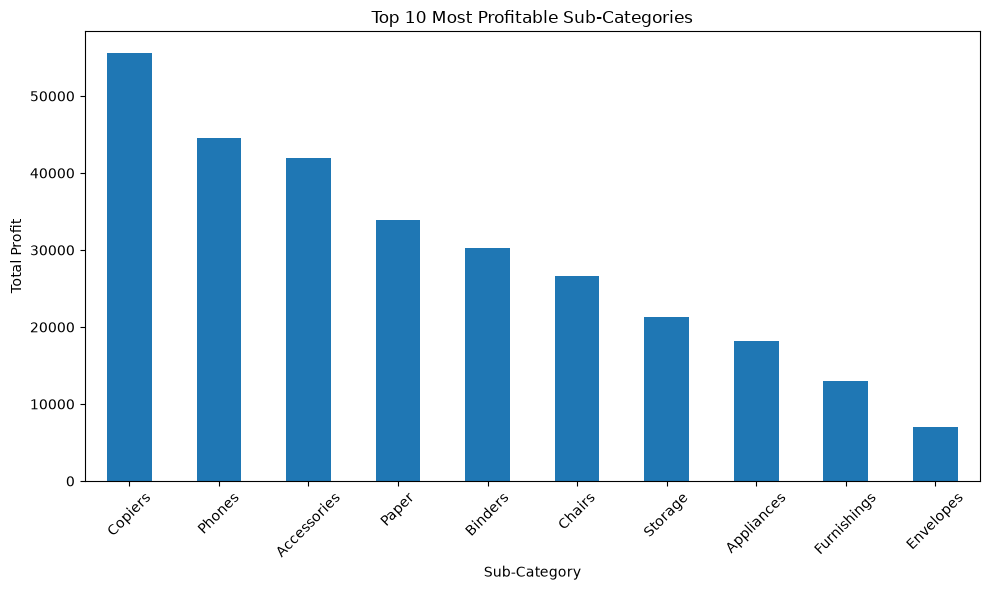

In [23]:
# Top 10 Profitable Sub-Categories

subcategory_profit = df.groupby(
    'Sub-Category'
)['Profit'].sum().sort_values(ascending=False)

top_10_profit = subcategory_profit.head(10)

print(top_10_profit)

top_10_profit.plot(
    kind='bar',
    figsize=(10, 6),
    title='Top 10 Most Profitable Sub-Categories',
    xlabel='Sub-Category',
    ylabel='Total Profit'
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../Visualizations/Sub_Category_Profit.png', bbox_inches='tight')
plt.show()

### 8.7 Dataset Columns and Analysis Limitations

In [24]:
print(df.columns.tolist())

['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit', 'Profit_Margin', 'Sales_Category', 'Profit_Status']


### 8.8 Sales by Shipping Mode

Ship Mode
Standard Class    1.357316e+06
Second Class      4.591770e+05
First Class       3.513805e+05
Same Day          1.283217e+05
Name: Sales, dtype: float64


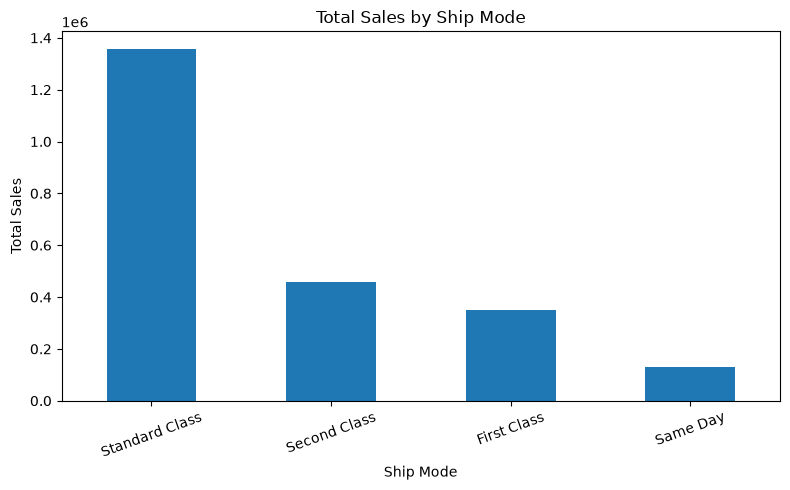

In [25]:
# Sales by Ship Mode

ship_sales = df.groupby('Ship Mode')['Sales'].sum().sort_values(
    ascending=False
)

print(ship_sales)

ship_sales.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Ship Mode',
    xlabel='Ship Mode',
    ylabel='Total Sales'
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('../Visualizations/Ship_Mode_Sales.png', bbox_inches='tight')
plt.show()

### 8.9 Sales by Customer Segment

Segment
Consumer       1.160833e+06
Corporate      7.060701e+05
Home Office    4.292927e+05
Name: Sales, dtype: float64


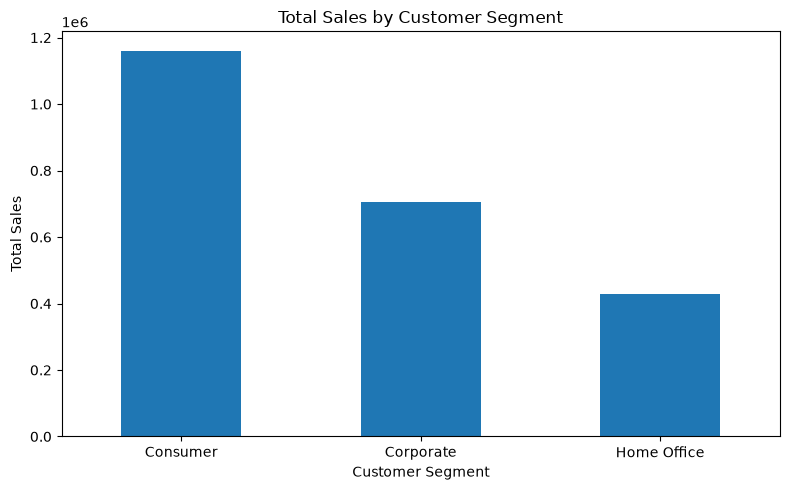

In [26]:
# Total Sales by Customer Segment

segment_sales = df.groupby('Segment')['Sales'].sum().sort_values(
    ascending=False
)

print(segment_sales)

segment_sales.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Customer Segment',
    xlabel='Customer Segment',
    ylabel='Total Sales'
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../Visualizations/Segment_Sales.png', bbox_inches='tight')
plt.show()

## 9. Correlation Analysis

The correlation matrix is used to examine linear relationships among Sales, Profit, Quantity, and Discount. Correlation does not establish causation.

             Sales    Profit  Quantity  Discount
Sales     1.000000  0.479067  0.200722 -0.028311
Profit    0.479067  1.000000  0.066211 -0.219662
Quantity  0.200722  0.066211  1.000000  0.008678
Discount -0.028311 -0.219662  0.008678  1.000000


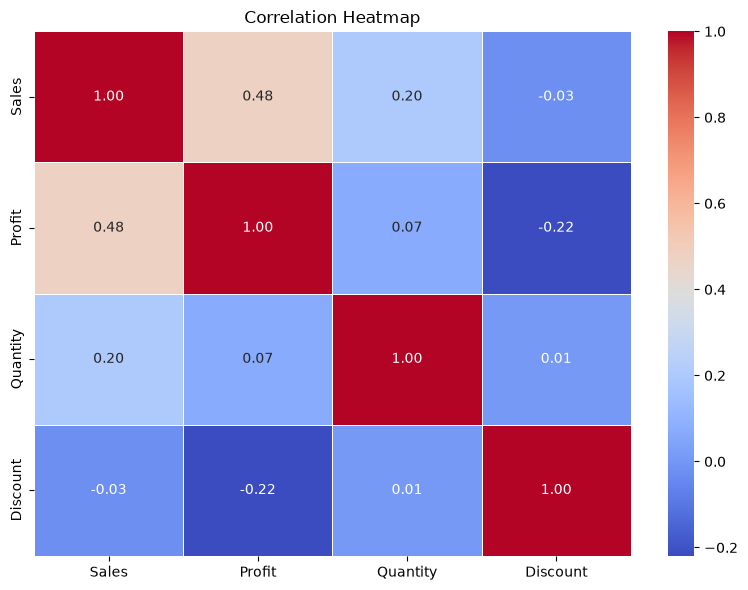

In [27]:
# Correlation Analysis

correlation = df[
    ['Sales', 'Profit', 'Quantity', 'Discount']
].corr()

print(correlation)

# Create Correlation Heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('../Visualizations/Correlation_Heatmap.png', bbox_inches='tight')
plt.show()

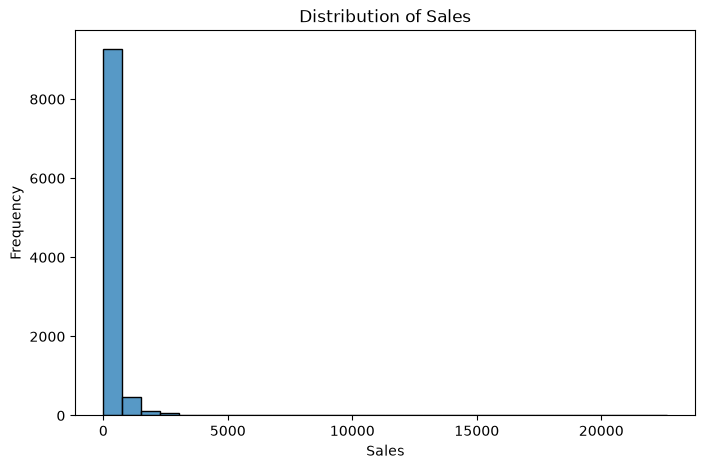

In [28]:
# Histogram of Sales

plt.figure(figsize=(8, 5))
sns.histplot(df['Sales'], bins=30, kde=False)
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.savefig('../Visualizations/Sales_Histogram.png', bbox_inches='tight')
plt.show()

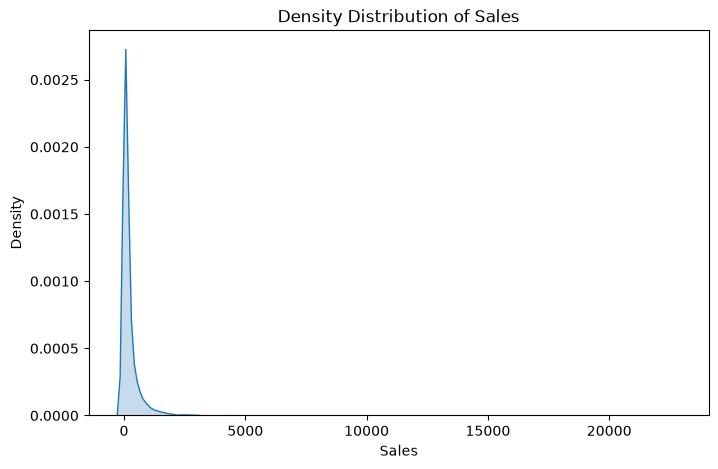

In [29]:
# Density Plot of Sales

plt.figure(figsize=(8, 5))
sns.kdeplot(df['Sales'], fill=True)
plt.title('Density Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Density')
plt.savefig('../Visualizations/Sales_Density_Plot.png', bbox_inches='tight')
plt.show()

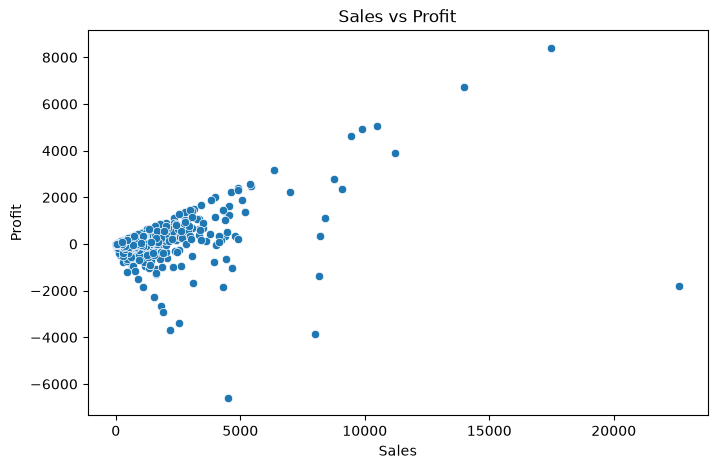

In [30]:
# Scatter Plot: Sales vs Profit

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Sales', y='Profit')
plt.title('Sales vs Profit')
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.savefig('../Visualizations/Sales_vs_Profit_Scatter.png', bbox_inches='tight')
plt.show()

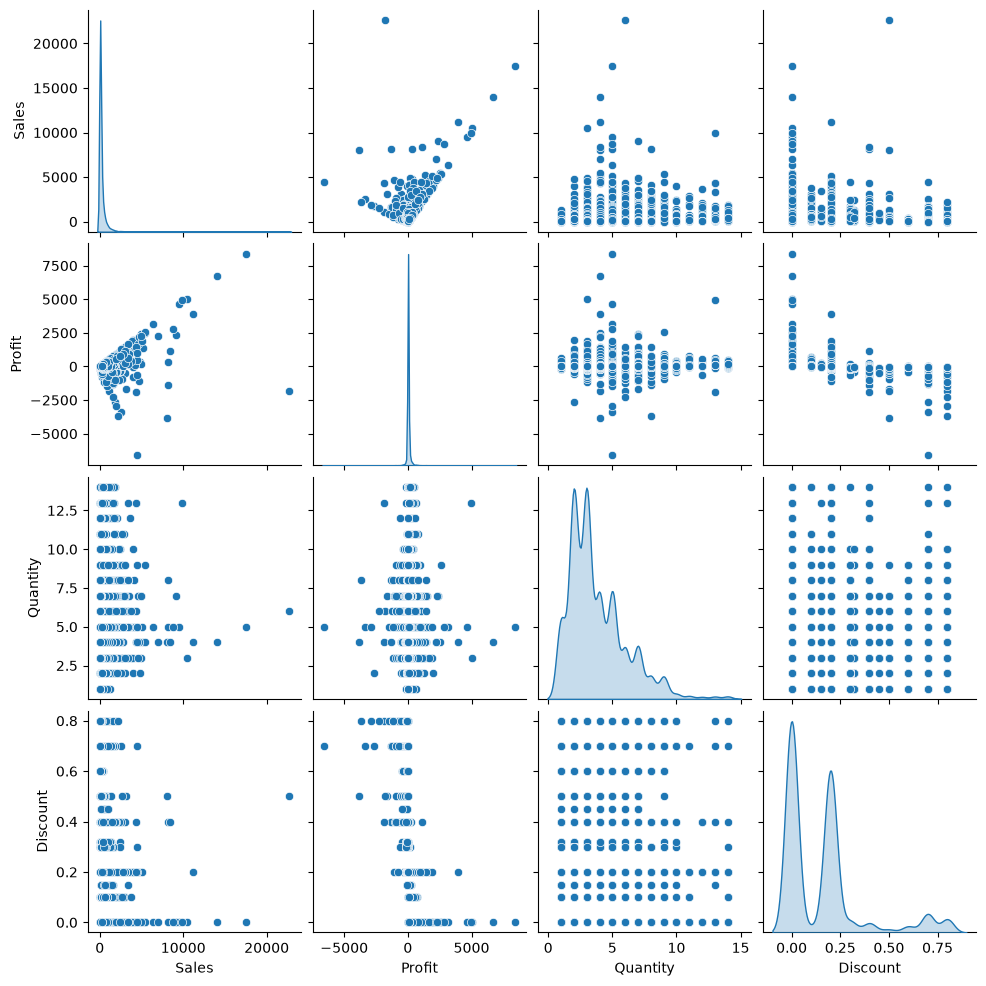

In [31]:
# Pair Plot of Numerical Features

sns.pairplot(
    df[['Sales', 'Profit', 'Quantity', 'Discount']],
    diag_kind='kde'
)

plt.savefig('../Visualizations/Sales_Pair_Plot.png', bbox_inches='tight')
plt.show()

In [32]:
overall_profit_margin = (
    df['Profit'].sum() / df['Sales'].sum()
) * 100

print("Overall Profit Margin:", round(overall_profit_margin, 2), "%")

Overall Profit Margin: 12.47 %


## 10. Key Findings and Business Insights

- Technology generated the highest total sales and profit among the three product categories.
- The West region recorded the highest sales and profit; the South recorded the lowest sales.
- Consumer customers contributed the highest sales among customer segments.
- Standard Class was the highest-sales shipping mode; Same Day was the lowest.
- Copiers were the most profitable sub-category.
- Average profit was negative at higher discount levels in this dataset, especially at 30%–80%; this is an observed association, not proof that discounts alone caused losses.
- The overall profit margin was **12.47%** (total profit divided by total sales).

## 11. Limitations

The available dataset does not include an Order Date or Customer ID column. Therefore, monthly/seasonal sales trends and customer-level retention or repeat-purchase analysis cannot be performed with this file.

## 12. Conclusion

The analysis shows that product category, region, shipping mode, customer segment, and discount level are useful dimensions for understanding Superstore performance. Technology and the West region are strong contributors, while Furniture profitability and high-discount transactions deserve closer review. These findings can support further business investigation and more informed sales and discount decisions.

In [33]:
# Save Cleaned Dataset
df.to_csv('../Dataset/Cleaned_SampleSuperstore.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [34]:
# Categorical Descriptive Statistics

categorical_columns = df.select_dtypes(include=['str']).columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts())


--- Ship Mode ---
Ship Mode
Standard Class    5955
Second Class      1943
First Class       1537
Same Day           542
Name: count, dtype: int64

--- Segment ---
Segment
Consumer       5183
Corporate      3015
Home Office    1779
Name: count, dtype: int64

--- Country ---
Country
United States    9977
Name: count, dtype: int64

--- City ---
City
New York City        914
Los Angeles          746
Philadelphia         536
San Francisco        506
Seattle              424
                    ... 
Aberdeen               1
Hagerstown             1
Arlington Heights      1
San Luis Obispo        1
Springdale             1
Name: count, Length: 531, dtype: int64

--- State ---
State
California              1996
New York                1127
Texas                    983
Pennsylvania             586
Washington               502
Illinois                 491
Ohio                     468
Florida                  383
Michigan                 254
North Carolina           249
Arizona                  

In [35]:
# Feature Selection

selected_features = [
    'Ship Mode',
    'Segment',
    'Region',
    'Category',
    'Sub-Category',
    'Sales',
    'Quantity',
    'Discount',
    'Profit',
    'Profit_Margin',
    'Sales_Category',
    'Profit_Status'
]

df_selected = df[selected_features]

print("Selected Features:")
print(df_selected.head())

print("\nSelected Dataset Shape:", df_selected.shape)

Selected Features:
        Ship Mode    Segment Region         Category Sub-Category     Sales  \
0    Second Class   Consumer  South        Furniture    Bookcases  261.9600   
1    Second Class   Consumer  South        Furniture       Chairs  731.9400   
2    Second Class  Corporate   West  Office Supplies       Labels   14.6200   
3  Standard Class   Consumer  South        Furniture       Tables  957.5775   
4  Standard Class   Consumer  South  Office Supplies      Storage   22.3680   

   Quantity  Discount    Profit  Profit_Margin Sales_Category Profit_Status  
0         2      0.00   41.9136          16.00         Medium        Profit  
1         3      0.00  219.5820          30.00           High        Profit  
2         2      0.00    6.8714          47.00            Low        Profit  
3         5      0.45 -383.0310         -40.00           High          Loss  
4         2      0.20    2.5164          11.25            Low        Profit  

Selected Dataset Shape: (9977, 12)


### Scaling and Normalization

Scaling and normalization were not performed because this project focuses on Exploratory Data Analysis (EDA) and does not involve building a machine learning model. Therefore, scaling was not necessary for the current analysis.

In [36]:
# Summary of Selected Features

print("Selected Dataset Information:")
df_selected.info()

print("\nStatistical Summary:")
print(df_selected.describe())

Selected Dataset Information:
<class 'pandas.DataFrame'>
Index: 9977 entries, 0 to 9993
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   Ship Mode       9977 non-null   str     
 1   Segment         9977 non-null   str     
 2   Region          9977 non-null   str     
 3   Category        9977 non-null   str     
 4   Sub-Category    9977 non-null   str     
 5   Sales           9977 non-null   float64 
 6   Quantity        9977 non-null   int64   
 7   Discount        9977 non-null   float64 
 8   Profit          9977 non-null   float64 
 9   Profit_Margin   9977 non-null   float64 
 10  Sales_Category  9977 non-null   category
 11  Profit_Status   9977 non-null   str     
dtypes: category(1), float64(4), int64(1), str(6)
memory usage: 1.4 MB

Statistical Summary:
              Sales     Quantity     Discount      Profit  Profit_Margin
count   9977.000000  9977.000000  9977.000000  9977.00000    9977.000